In [2]:

import os
import unstructured_pytesseract

tesseract_path = r"C:\Program Files\Tesseract-OCR\tesseract.exe"

# Verify that the executable exists
assert os.path.isfile(tesseract_path), (
    f"Tesseract not found at: {tesseract_path}"
)

# Tell Unstructured's OCR wrapper where Tesseract is
unstructured_pytesseract.pytesseract.tesseract_cmd = (
    tesseract_path
)

from unstructured.partition.pdf import partition_pdf

# Keep your existing partition_pdf() code below


from unstructured.partition.pdf import partition_pdf

output_path = "./content/"
file_path = output_path + 'DM.pdf'

# Reference: https://docs.unstructured.io/open-source/core-functionality/chunking
chunks = partition_pdf(
    filename=file_path,
    infer_table_structure=True,            # extract tables
    strategy="hi_res",                     # mandatory to infer tables

    extract_image_block_types=["Image", "Formula"],   # Add 'Table' to list to extract image of tables
    image_output_dir_path=output_path,   # if None, images and tables will saved in base64

    extract_image_block_to_payload=True,   # if true, will extract base64 for API usage

    chunking_strategy="by_title",          # or 'basic'
    max_characters=10000,                  # defaults to 500
    combine_text_under_n_chars=2000,       # defaults to 0
    new_after_n_chars=6000,

    # extract_images_in_pdf=True,          # deprecated
)

c:\Users\debra\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights: 100%|██████████| 367/367 [00:00<00:00, 2625.03it/s]


In [3]:
# We get 2 types of elements from the partition_pdf function
set([str(type(el)) for el in chunks])

{"<class 'unstructured.documents.elements.CompositeElement'>"}

In [49]:
# Each CompositeElement containes a bunch of related elements.
# This makes it easy to use these elements together in a RAG pipeline.

chunks[4].metadata.orig_elements


In [5]:
# This is what an extracted image looks like.
# It contains the base64 representation only because we set the param extract_image_block_to_payload=True

elements = chunks[4].metadata.orig_elements
chunk_images = [el for el in elements if 'FigureCaption' in str(type(el))]
chunk_images[0].to_dict()

{'type': 'FigureCaption',
 'element_id': 'b5ab8ef2-0b28-430f-870c-28d5d3410836',
 'text': 'FIG. 1: Annihilations of RHNs to Majorons',
 'metadata': {'detection_class_prob': 0.8838571906089783,
  'is_extracted': 'true',
  'coordinates': {'points': ((np.float64(970.4071044921875),
     np.float64(1558.7918933333333)),
    (np.float64(970.4071044921875), np.float64(1583.69856)),
    (np.float64(1471.9786376953125), np.float64(1583.69856)),
    (np.float64(1471.9786376953125), np.float64(1558.7918933333333))),
   'system': 'PixelSpace',
   'layout_width': 1700,
   'layout_height': 2200},
  'last_modified': '2026-10-12T19:35:04',
  'filetype': 'PNG',
  'languages': ['eng'],
  'page_number': 4}}

In [6]:
# separate tables from texts
tables = []
texts = []

for chunk in chunks:
    if "Table" in str(type(chunk)):
        tables.append(chunk)

    if "CompositeElement" in str(type((chunk))):
        texts.append(chunk)

In [62]:
# Get the images from the CompositeElement objects
def get_images_base64(chunks):
    images_b64 = []
    image_captions = []
    for chunk in chunks:
        if "CompositeElement" in str(type(chunk)):
            chunk_els = chunk.metadata.orig_elements
            for i, el in enumerate(chunk_els):
                if "Image" in str(type(el)):
                    images_b64.append(el.metadata.image_base64)
                    
                    # Prevent another potential IndexError if an Image is the absolute last element
                    if i + 1 < len(chunk_els) and "FigureCaption" in str(type(chunk_els[i+1])):
                        image_captions.append(chunk_els[i+1].text)
                        
                        # Use -2 to check the previously added caption
                        if len(image_captions) > 1 and image_captions[-2] == "None":
                            image_captions[-2] = chunk_els[i+1].text
                    else:
                        image_captions.append("None")
    return images_b64, image_captions


# Get the formula from the CompositeElement objects
def get_formulas_base64(chunks):
    formulas_b64 = []
    for chunk in chunks:
        if "CompositeElement" in str(type(chunk)):
            chunk_els = chunk.metadata.orig_elements
            for el in chunk_els:
                if "Formula" in str(type(el)):
                    formulas_b64.append(el.metadata.image_base64)
    return formulas_b64

images, captions = get_images_base64(chunks)
formulas = get_formulas_base64(chunks)

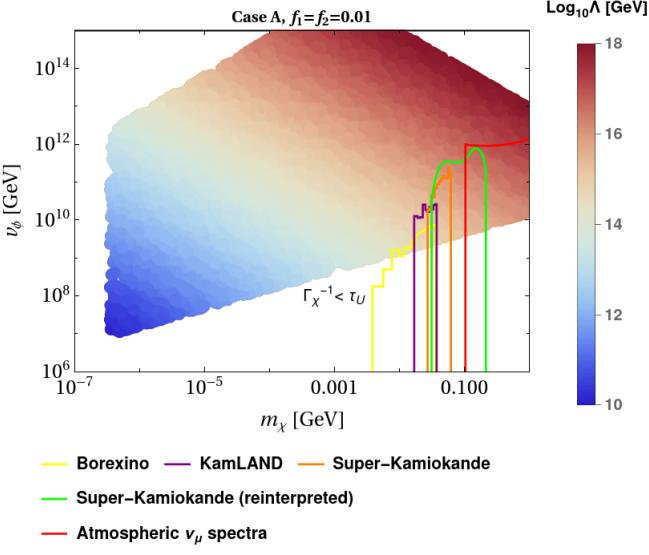

In [32]:
import base64
from IPython.display import Image, display

def display_base64_image(base64_code):
    # Decode the base64 string to binary
    image_data = base64.b64decode(base64_code)
    # Display the image
    display(Image(data=image_data))

display_base64_image(images[8])

In [9]:
print(captions[0])

FIG. 1: Annihilations of RHNs to Majorons


In [15]:
from langchain_ollama import ChatOllama
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_core.messages import HumanMessage

In [11]:
#Prompt
prompt_text = """
You are an assistant tasked with summarizing tables and text
from scientific research papers.

Give a concise, accurate summary of the supplied table or text.
Preserve technical terminology, numerical values, and key findings.

Respond only with the summary.

Table or text chunk:
{element}
"""

prompt = ChatPromptTemplate.from_template(prompt_text)


#Summary chain
model = ChatOllama(
    model="qwen2.5vl:3b",
    temperature=0.5
)

summarize_chain = (
    {"element": lambda x: x}
    | prompt
    | model
    | StrOutputParser()
)

In [12]:
text_summaries = summarize_chain.batch(
    texts,
    config={"max_concurrency": 3}
)

tables_html = [
    table.metadata.text_as_html
    for table in tables
]

table_summaries = summarize_chain.batch(
    tables_html,
    config={"max_concurrency": 2}
)

In [13]:
text_summaries

['The research explores the potential of Majorons, pseudo-Nambu-Goldstone bosons resulting from the spontaneous breaking of global lepton number symmetry, ( U(1)L ), as viable freeze-in type dark matter candidates in a mass range of O(keV-GeV). The proposal is based on the explicit higher-dimensional Lepton Number Breaking (LNB) operator, which leads to Majoron production through the annihilations of right-handed neutrinos. (RHNs). The study aims to broaden the Majoron mass range while maintaining minimalism and naturalness, avoiding explicit Higgs portal interactions. and instead introduces a dimension-5 LNB operator. The research focuses on the lighter side of Majoron mass, O(keV-GeV), which can be experimentally probed by various direct and indirect searches. monoenergetic neutrino flux in experiments like Borexino, KamLAND, and Super-Kamiokande. (SK). Sensitive bounds from various γ-ray observations such as INTEGRAL, COMP-TEL/EGRET, and Fermi-LAT are also applicable in this mass re

In [63]:
print(len(images))
print(len(captions))
captions[0]

12
12


'FIG. 1: Annihilations of RHNs to Majorons'

In [64]:
prompt_template = """
You are analyzing a figure extracted from a scientific research paper.

Your task is to produce a scientifically accurate description of the image, using the provided figure caption as essential context.

FIGURE CAPTION:
{caption}

INSTRUCTIONS:

1. Read and interpret the figure caption BEFORE analyzing the image. The caption describes the scientific purpose, subject, and context of the figure. Use this information to guide your interpretation of the visual content.

2. Identify the type of figure: plot, diagram, schematic, photograph, equation, table, or a combination of these.

3. Connect the visible content to the caption:
   - Identify the objects, physical quantities, processes, or theoretical concepts mentioned in the caption that are actually visible in the image.
   - Explain how the visible elements relate to the scientific subject described in the caption.
   - Use terminology from the caption where appropriate.
   - If the caption specifies a physical process, model, experimental setup, or theoretical relationship, interpret the image in that context.

4. If the image contains graphs, describe the axes, variables, units, curves, legends, trends, important features, and relationships. Use the caption to interpret what the plotted quantities represent. Do not invent axis labels, numerical values, or trends that cannot be established from the image.

5. If the image contains a schematic or scientific diagram, describe its components, labels, arrows, connections, and the physical or mathematical process they represent, informed by the caption.

6. If the image contains multiple panels, describe each panel separately and explain how the panels relate to the caption and to each other.

7. Distinguish between information explicitly provided by the caption and information directly observable in the image. Do not invent scientific conclusions that are unsupported by either source.

8. If the caption describes something that is not clearly visible, acknowledge the uncertainty rather than ignoring the caption or hallucinating visual details.

OUTPUT REQUIREMENTS:
Write a detailed, coherent scientific description suitable for indexing and retrieval in a retrieval-augmented generation (RAG) system. Prioritize scientific meaning and relationships over superficial visual appearance.

Return only the image summary. Do not repeat these instructions.
"""

def summarize_image(image, caption):
    # Strip the data URL prefix if present
    if image.startswith("data:"):
        header, image = image.split(",", 1)
        mime_type = header.split(";")[0].split(":")[1]
    else:
        mime_type = "image/jpeg"

    # Validate that the image is base64
    base64.b64decode(image, validate=True)

    message = HumanMessage(
        content=[
            {
                "type": "text",
                "text": prompt_template.format(
                    caption=caption or ""
                )
            },
            {
                "type": "image",
                "base64": image,
                "mime_type": mime_type
            }
        ]
    )

    response = model.invoke([message])
    return StrOutputParser().invoke(response)


assert len(images) == len(captions)

image_summaries = [
    summarize_image(image, caption)
    for image, caption in zip(images, captions)
]

In [65]:
image_summaries

['The figure represents a schematic diagram illustrating the annihilation process of Right-handed Neutrinos (RHNs) to Majorons. The diagram consists of two lines labeled "N_i" connected by a dashed arrow, indicating the interaction between RHNs and Majorons. The dashed arrow is labeled with the symbol "χ," representing the Majoron field. The text "≈ 1/Λ" suggests that the interaction strength is inversely proportional to a characteristic length scale Λ, indicating a form of quantum tunneling or a similar process involving a critical length scale. The overall structure of the diagram aims to convey the basic concept of RHN annihilation to Majorons, highlighting the interaction mechanism and its scaling behavior.',
 'The provided figure is a plot that represents the parameter space in the vϕ vs mχ plane for Case A, where degenerate RHNs are in thermal equilibrium at the temperature of 10^14 GeV. The figure shows the relic satisfied parameter space, with Λ represented by a color bar on th

In [ ]:
print(len(image_summaries))